# **Regression Model: Boston House Price Prediction**

## **Introduction**
------------------------------

This notebook explores the relationship between neighborhood characteristics and median home values in the historical Boston Housing dataset. It follows a regression modeling workflow that includes exploratory data analysis, preprocessing, feature engineering, model development, and diagnostic evaluation.
The primary objective is to develop a Ridge regression model that predicts median neighborhood-level housing values while examining the limitations and assumptions of the modeling approach.


## **Objective**
-------------------------------

The problem at hand is to **predict the housing prices of a town or a suburb based on the features of the locality provided to us**. In the process, we need to **identify the most important features affecting the price of the house**. We need to employ techniques of data preprocessing and build a linear regression model that predicts the prices for the unseen data.

## **Dataset**
---------------------------

Each record in the database describes a house in Boston suburb or town. The data was drawn from the Boston Standard Metropolitan Statistical Area (SMSA) in 1970. Detailed attribute information can be found below:

Attribute Information:

- **CRIM:** Per capita crime rate by town
- **ZN:** Proportion of residential land zoned for lots over 25,000 sq.ft.
- **INDUS:** Proportion of non-retail business acres per town
- **CHAS:** Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)
- **NOX:** Nitric Oxide concentration (parts per 10 million)
- **RM:** The average number of rooms per dwelling
- **AGE:** Proportion of owner-occupied units built before 1940
- **DIS:** Weighted distances to five Boston employment centers
- **RAD:** Index of accessibility to radial highways
- **TAX:** Full-value property-tax rate per 10,000 dollars
- **PTRATIO:** Pupil-teacher ratio by town
- **LSTAT:** % lower status of the population
- **MEDV:** Median value of owner-occupied homes in 1000 dollars

## **Importing the necessary libraries**

In [310]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error

from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

### Loading the dataset

In [311]:
df = pd.read_csv('Boston.csv')

## Data Overview

- Observations
- Sanity checks

In [312]:
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2


In [313]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    int64  
 10  PTRATIO  506 non-null    float64
 11  LSTAT    506 non-null    float64
 12  MEDV     506 non-null    float64
dtypes: float64(10), int64(3)
memory usage: 51.5 KB


In [314]:
df.isnull().sum()

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
LSTAT      0
MEDV       0
dtype: int64

## Exploratory Data Analysis (EDA)

**Questions:**

1. What does the distribution of 'MEDV' look like?
2. What can we infer form the correlation heatmap? Is there correlation between the dependent and independent variables?
3. What are all the inferences that can be found by doing univariate analysis for different variables?
4. Do bivariate analysis to visualize the relationship between the features having significant correlations (>= 0.7 or <= -0.7)

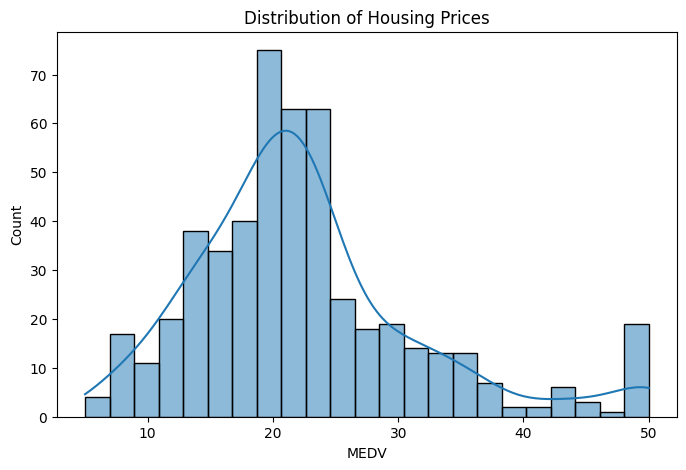

In [315]:
plt.figure(figsize=(8,5))
sns.histplot(df['MEDV'], kde=True)
plt.title('Distribution of Housing Prices')
plt.show()

#slightly right-skewed
#cap of $50,000 on prices instead of the actual median values will weaken the model's ability to distinguish between higher-priced suburbs

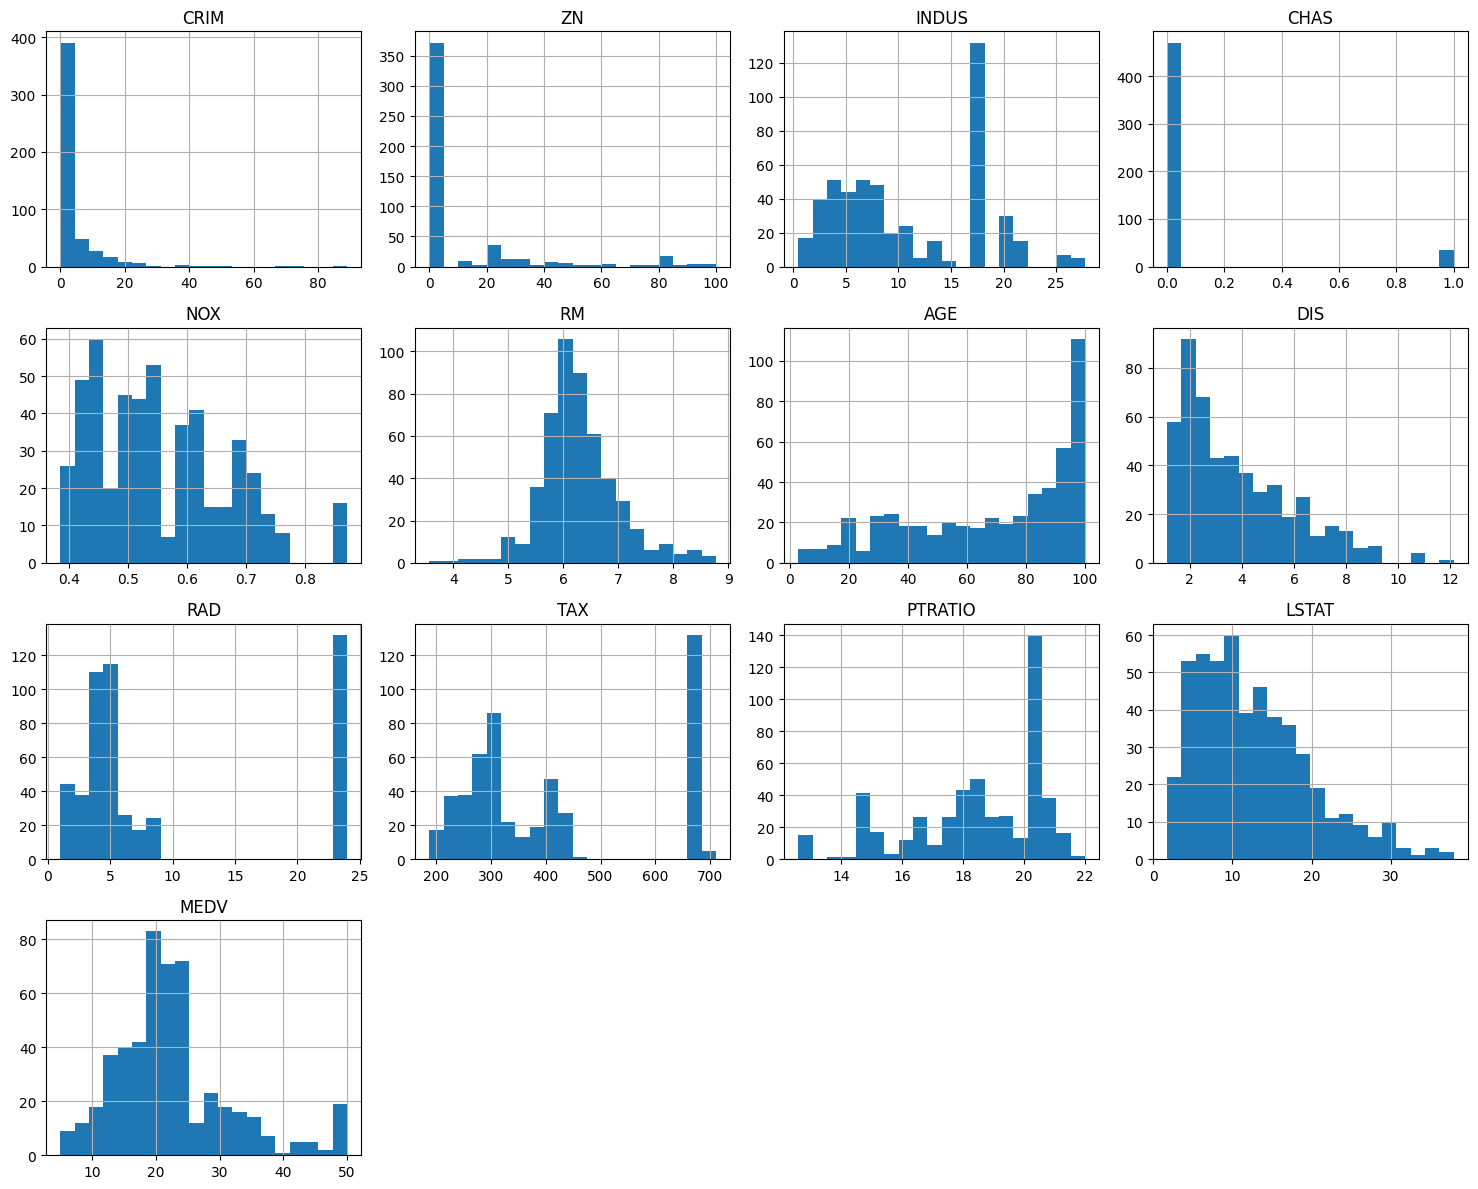

In [316]:
num_cols = df.select_dtypes(include=['int64','float64']).columns

df[num_cols].hist(
    figsize=(15,12),
    bins=20
)
plt.tight_layout()
plt.show()

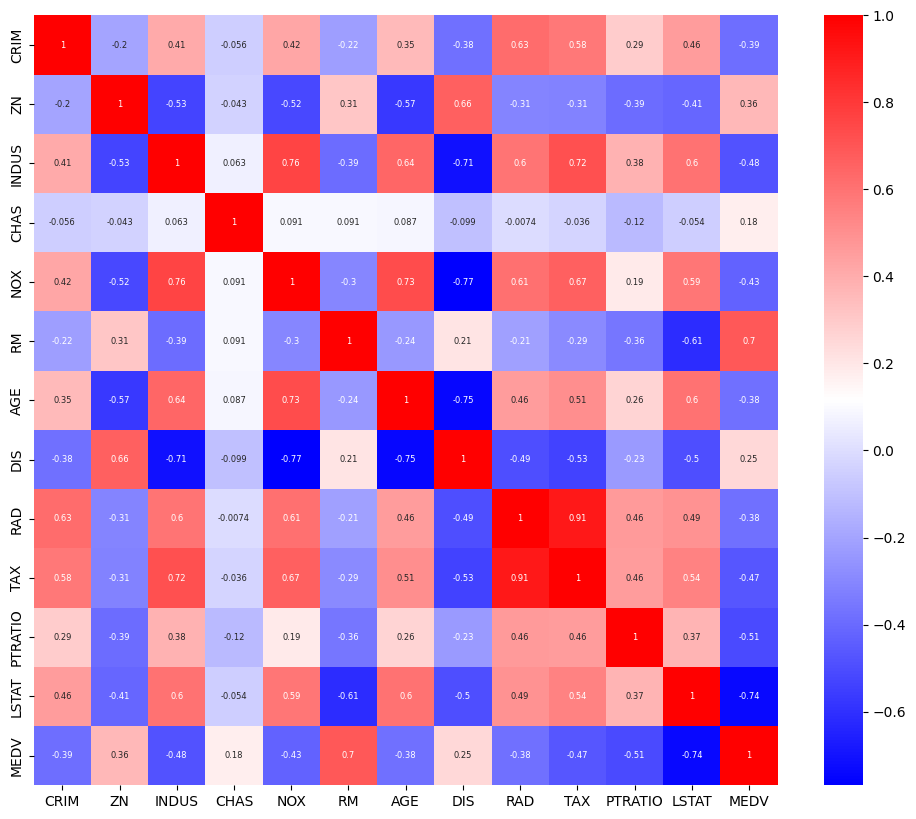

In [317]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(12,10))
sns.heatmap(
    corr,
    cmap='bwr',
    annot=True,
    annot_kws={"size": 6}
)
plt.show()

#the strongest correlations with MEDV are LSTAT (negative correlation) and RM (positive correlation)
#PTRATIO, INDUS, and TAX also have notable correlations

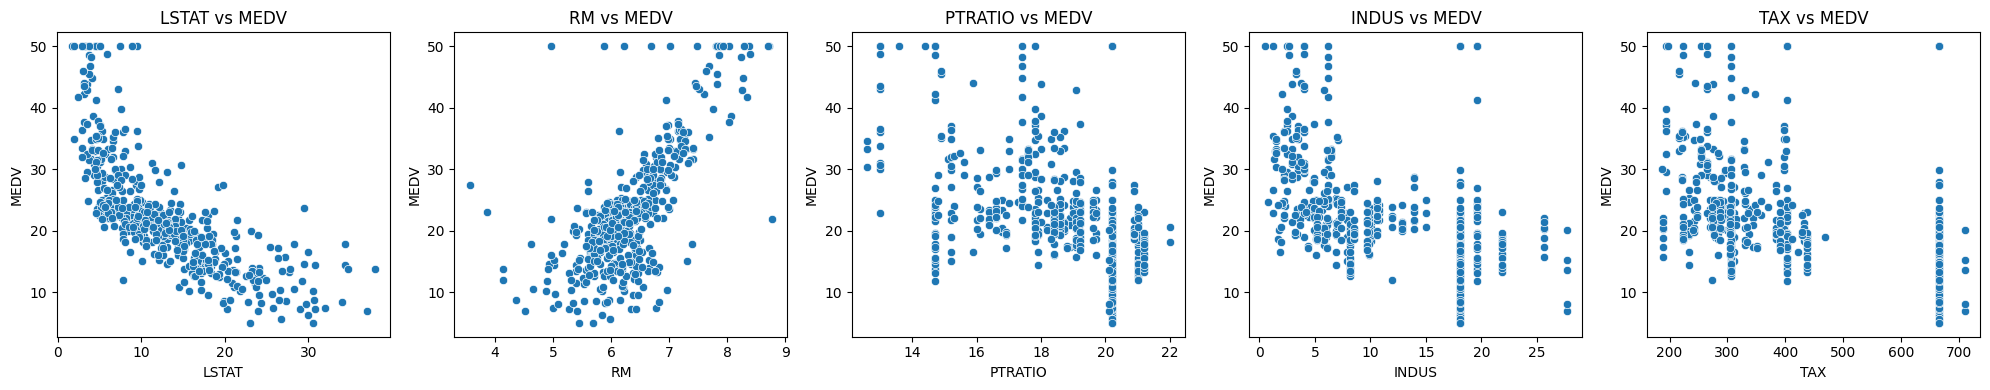

In [318]:
#creating scatterplots between price and the variables most strongly correlated with it

features = ['LSTAT', 'RM', 'PTRATIO', 'INDUS', 'TAX']

fig, axes = plt.subplots(1, len(features), figsize=(20, 4))

for i, feature in enumerate(features):
    sns.scatterplot(
        x=df[feature],
        y=df['MEDV'],
        ax=axes[i]
    )
    axes[i].set_title(f'{feature} vs MEDV')

plt.tight_layout()
plt.show()

## Data Preprocessing

- Missing value treatment
- Log transformation of dependent variable if skewed
- Feature engineering (if needed)
- Outlier detection and treatment (if needed)
- Preparing data for modeling
- Any other preprocessing steps (if needed)

In [343]:
#checking if any skewed variables can be log scaled
df_model = df

df[['CRIM','ZN','INDUS','NOX','RM','AGE','DIS','RAD','TAX','PTRATIO','LSTAT']].skew().sort_values(ascending=False)

CRIM       5.223149
ZN         2.225666
DIS        1.011781
RAD        1.004815
LSTAT      0.906460
NOX        0.729308
TAX        0.669956
RM         0.403612
INDUS      0.295022
AGE       -0.598963
PTRATIO   -0.802325
dtype: float64

Among the skew values above, 4 variables have a skew magnitude greater than 1. We will apply log transforms to these features.

In [320]:
log_features = ['CRIM', 'DIS', 'ZN', 'RAD']
numeric_features = [
    'RM', 'LSTAT', 'PTRATIO', 'INDUS',
    'NOX', 'AGE', 'TAX', 'CHAS'
]

In [321]:
X = df_model.drop(columns=['MEDV'])
y = df_model['MEDV']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

## Model Building - Linear Regression

In [322]:
#model = LinearRegression()
log_transformer = Pipeline(steps=[
    ('log', FunctionTransformer(np.log1p))
])

preprocess = ColumnTransformer(
    transformers=[
        ('log', FunctionTransformer(np.log1p, feature_names_out="one-to-one"), log_features),
        ('num', StandardScaler(), numeric_features)
    ]
)

model = Pipeline(steps=[
    ('preprocess', preprocess),
    ('regressor', Ridge(alpha=10))
])
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['CRIM','ZN','INDUS',...,'TAX','PTRATIO','LSTAT']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('log', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with

In [323]:
#matching the linear coefficients with their features

feature_names = model.named_steps['preprocess'].get_feature_names_out()

coef = model.named_steps['regressor'].coef_

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coef
})

coef_df['Feature'] = (
    coef_df['Feature']
    .str.replace('log__', '')
    .str.replace('num__', '')
)

coef_df = coef_df.sort_values('Coefficient', ascending=False)

coef_df

,Feature,Coefficient
4,RM,3.211739
3,RAD,1.627755
11,CHAS,0.858457
2,ZN,0.043949
7,INDUS,0.032212
9,AGE,-0.109126
0,CRIM,-0.857419
10,TAX,-1.048696
8,NOX,-1.743400
6,PTRATIO,-1.896673


In [324]:
y_pred = model.predict(X_test)
y_train_pred = model.predict(X_train)

## Model Performance Check

1. How does the model is performing? Check using Rsquared, RSME, MAE, MAPE
2. Is there multicollinearity? Check using VIF
3. How does the model is performing after cross validation?

In [325]:
#checking Rsquared

train_Rsquared = r2_score(y_train, y_train_pred)
train_Rsquared

0.7394017197461542

In [326]:
test_Rsquared = r2_score(y_test, y_pred)
test_Rsquared

0.6790071156224932

In [327]:
#checking RMSE

rmse = root_mean_squared_error(y_test, y_pred)
rmse

4.851764893206049

In [328]:
#checking MAE

mae = mean_absolute_error(y_test, y_pred)
mae

3.0466970212087054

In [329]:
#checking MAPE

mape = mean_absolute_percentage_error(y_test, y_pred)
mape

0.1577854426897205

In [330]:
#Using K-fold cross validation to ensure model's validity

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    model,
    X,
    y,
    cv=cv,
    scoring='r2'
)

print(scores)
print(scores.mean())
print(scores.std())

[0.67900712 0.71370176 0.7004075  0.76916054 0.69367045]
0.7111894725400632
0.031067111425832905


The model is performing moderately well. 0.739 Rsquared on the training data and 0.679 Rsquared suggests that there is some slight overfitting but it is minimal. Error metrics suggest the model is incorporating most of the trends from the data, but there is still room for improvement on a 15.7% mean average error percentage and a 0.711 mean cross-validation Rsquared.

To try and address this, I'm going to build a new model that allows polynomial interactions for the two most nonlinear features, LSTAT and RM, but removes the log transformations and then compare the results.

In [331]:
poly_features = ['RM', 'LSTAT']

other_features = [
    'CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX',
    'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO'
]

poly_transformer = Pipeline([
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('scale', StandardScaler())
])

preprocess = ColumnTransformer(
    transformers=[
        ('poly', poly_transformer, poly_features),
        ('num', StandardScaler(), other_features)
    ]
)

model = Pipeline([
    ('preprocess', preprocess),
    ('regressor', Ridge(alpha=10))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_train_pred = model.predict(X_train)

In [332]:
#checking Rsquared

train_Rsquared = r2_score(y_train, y_train_pred)
train_Rsquared

0.805254879321161

In [333]:
test_Rsquared = r2_score(y_test, y_pred)
test_Rsquared

0.7837402737664171

In [334]:
#checking RMSE

rmse = root_mean_squared_error(y_test, y_pred)
rmse

3.982354061346677

In [335]:
#checking MAE

mae = mean_absolute_error(y_test, y_pred)
mae

2.5055658008809036

In [336]:
#checking MAPE

mape = mean_absolute_percentage_error(y_test, y_pred)
mape

0.12105490872455134

In [337]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    model,
    X,
    y,
    cv=cv,
    scoring='r2'
)

print(scores)
print(scores.mean())
print(scores.std())

[0.78374027 0.80190565 0.75427221 0.85182666 0.73593017]
0.7855349905181952
0.04025867436549889


The updated model has significantly improved performance across all error metrics and validation. The training and test Rsquared values are very close, at 0.805 and 0.784 respectively. The Rsquared values for the cross validation folds have significantly improved as well (0.711 for the log transform model vs 0.786 for the polynomial features model).

This is the version of the model that will be used.

## Checking Linear Regression Assumptions

- In order to make statistical inferences from a linear regression model, it is important to ensure that the assumptions of linear regression are satisfied.

In [338]:
#assessing the Variance Inflation Factor for the raw features

X_vif = X[other_features + poly_features]

vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

print(vif_data.sort_values("VIF", ascending=False))

    feature        VIF
9   PTRATIO  78.727100
10       RM  76.160431
4       NOX  73.077558
8       TAX  61.225416
5       AGE  21.350797
7       RAD  14.732498
6       DIS  14.576652
2     INDUS  14.446693
11    LSTAT  11.040786
1        ZN   2.842980
0      CRIM   2.077944
3      CHAS   1.148528


There are 4 features that indicate a very high degree of multicollinearity: PTRATIO, RM, NOX, and TAX. This is expected in housing data, many of the variables are strongly correlated with one another. The model cannot sufficiently separate the individual effects of these 4 features.

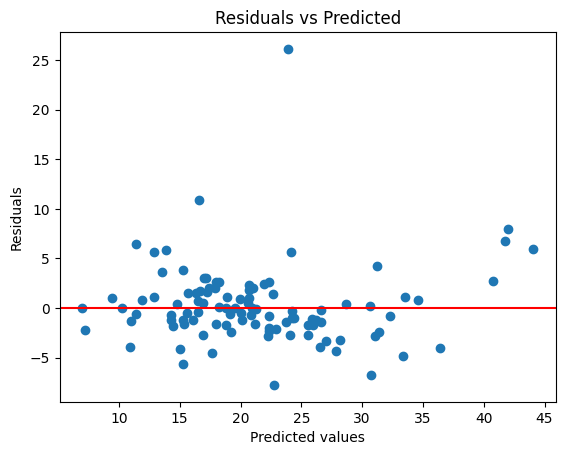

In [339]:
#plotting residuals for each predicated value to see whether data is centered at 0 residual and assess potential non-linearity

residuals = y_test - y_pred

plt.scatter(y_pred, residuals)
plt.axhline(0, color='red')
plt.xlabel("Predicted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted")
plt.show()

Residuals are centered at 0 and the spread is somewhat consistent across low and high predicted values. This indicates minimal bias across predicted values and is a strong sign for the validity of the model. There is one noteworthy outlier.

In [340]:
#Utilizing the Breusch-Pagan test to assess possible heteroskedasticity

lm = sm.OLS(y, sm.add_constant(X)).fit()

het_breuschpagan(lm.resid, lm.model.exog)

(np.float64(63.30237054711779),
 np.float64(5.606576617516915e-09),
 np.float64(5.874602023940182),
 np.float64(1.4084399829583695e-09))

There is clear heteroskedasticity present in the model, indicating the errors of the model are not constant across prediction values.

The VIF analysis revealed substantial multicollinearity among several predictors, particularly PTRATIO, RM, NOX, and TAX, all of which exhibited very high VIF values (>60). This indicates strong linear dependencies among predictors.

However, since the goal of the model is prediction rather than inference, and Ridge regression is used, the impact of multicollinearity is mitigated through L2 regularization, which stabilizes coefficient estimates by shrinking correlated predictors together.

## Final Model

In [341]:
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['CRIM','ZN','INDUS',...,'TAX','PTRATIO','LSTAT']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('poly', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated wit

In [342]:
#matching the linear coefficients with their features

feature_names = model.named_steps['preprocess'].get_feature_names_out()

coef = model.named_steps['regressor'].coef_

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coef
})

coef_df['Feature'] = (
    coef_df['Feature']
    .str.replace('log__', '')
    .str.replace('num__', '')
)

coef_df = coef_df.sort_values('Coefficient', ascending=False)

coef_df

,Feature,Coefficient
2,poly__RM^2,3.762786
4,poly__LSTAT^2,3.295463
12,RAD,1.524162
8,CHAS,0.665294
6,ZN,0.307273
10,AGE,0.230970
7,INDUS,0.153604
0,poly__RM,0.112973
5,CRIM,-1.159476
13,TAX,-1.251071


## Actionable Insights and Recommendations 

- The 3 largest coefficients for this linear regression model are all polynomial combinations of the RM (average rooms per dwelling) and LSTAT (lower socioeconomic status percentage of the population) variables, with the most highly correlated feature being the product of the two. These are the metrics that are most predictive of median housing price of a Boston locality.
- DIS (weighted distance to Boston employment centers), NOX (nitric oxide concentration), PTRATIO (pupil to teacher ratio by town), and RAD (accessibility to radial highways) are also moderately predictive of median housing prices.
- Because many of the features of housing data are inherently correlated, it is difficult for a linear regression model to fully separate the effects of each variable. The model is performing very well in spite of this, with a 0.786 mean cross-validation Rsquared and a 12.1% mean average percentage error.


## Conclusions

The final Ridge regression model incorporating polynomial features for RM and LSTAT improved predictive performance over the initial model. The results suggest that housing values are influenced by relationships that are not fully captured through simple linear terms.

Model evaluation showed reasonably consistent performance across the training, test, and cross-validation results. However, diagnostic analysis identified multicollinearity and heteroskedasticity, which should be considered when interpreting the model and its coefficients.

Overall, this project demonstrates the importance of combining exploratory analysis, feature engineering, model evaluation, and regression diagnostics when developing a predictive model.